<a href="https://colab.research.google.com/github/abekpudo/my-ml-zoomcamp/blob/main/Module_2_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [63]:
# importing needed libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [64]:
# Fetching the raw dataset

!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

--2026-10-10 02:36:02--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv.2’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.04s   

2026-10-10 02:36:02 (14.0 MB/s) - ‘car_fuel_efficiency_2026.csv.2’ saved [635180/635180]



In [65]:
# Reading and displaying the dataset

df = pd.read_csv('car_fuel_efficiency_2026.csv')
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [66]:
# Analysing the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  object 
 2   fuel_type            10000 non-null  object 
 3   drivetrain           10000 non-null  object 
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), object(3)
memory usage: 859.5+ KB


In [67]:
# Displaying the column names

df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='object')

In [68]:
# Filtering the dataset

cars = df[['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight', 'fuel_efficiency_mpg']]

cars.head()

,model_year,engine_displacement,horsepower,vehicle_weight,fuel_efficiency_mpg
0,2006,2180,243.0,3870,31.9
1,2008,2390,272.0,4210,31.3
2,1996,2320,267.0,4240,27.5
3,1989,2130,258.0,4490,28.5
4,1994,2580,304.0,4510,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

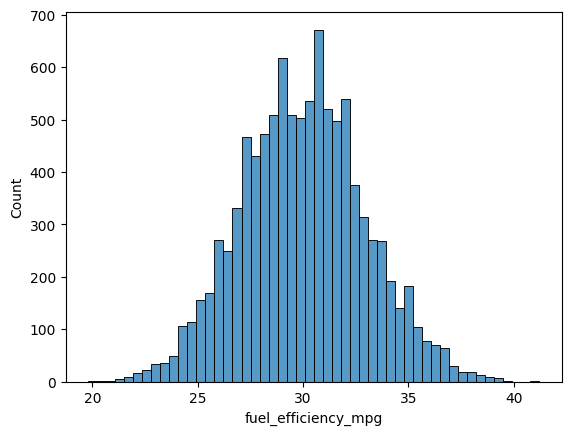

In [69]:
# EDA: Looking at the distribution of the target variable

sns.histplot(cars.fuel_efficiency_mpg, bins=50) # Normally distributed

In [70]:
# Q1. Column with missing values

cars.isnull().sum() # horsepower

,0
model_year,0
engine_displacement,0
horsepower,877
vehicle_weight,0
fuel_efficiency_mpg,0


In [71]:
# Q2. Median (50th percentile) of horsepower

cars.horsepower.describe() #254

,horsepower
count,9123.000000
mean,254.446016
std,22.844613
min,171.000000
25%,239.000000
50%,254.000000
75%,270.000000
max,334.000000


In [72]:
# Shuffling and splitting the filtered dataset

n = len(cars)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

cars_train = cars.iloc[idx[:n_train]]
cars_val = cars.iloc[idx[n_train:n_train + n_val]]
cars_test = cars.iloc[idx[n_train + n_val:]]

# Confirm the shapes and columns
print(n, n_train, n_val, n_test)
print(cars_train.shape)
print(cars_train.columns)

10000 6000 2000 2000
(6000, 5)
Index(['model_year', 'engine_displacement', 'horsepower', 'vehicle_weight',
       'fuel_efficiency_mpg'],
      dtype='object')


In [73]:
# Preparing target values and removing them from the feature sets

y_train = cars_train.fuel_efficiency_mpg.values
y_val = cars_val.fuel_efficiency_mpg.values
y_test = cars_test.fuel_efficiency_mpg.values

del cars_train['fuel_efficiency_mpg']
del cars_val['fuel_efficiency_mpg']
del cars_test['fuel_efficiency_mpg']

In [74]:
# Create the linear regression model

def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)


In [75]:
# Q3. Filling missing values
# Option 1: Filling with 0

X_train_zero = cars_train.fillna(0).values
w0_zero, w_zero = train_linear_regression(X_train_zero, y_train)

print(f'Bias/Intercept: {w0_zero}')
print(f'Weights: {w_zero}')

# Evaluating the model
X_val_zero = cars_val.fillna(0).values
y_pred_zero = w0_zero + X_val_zero.dot(w_zero)
rmse_zero = rmse(y_val, y_pred_zero)

print(f'\nRMSE with 0 filling: {round(rmse_zero, 3)}')

Bias/Intercept: -153.8849618825958
Weights: [ 1.02146785e-01 -1.51505520e-03 -4.74024796e-06 -3.95418397e-03]

RMSE with 0 filling: 2.205


In [76]:
# Option 2: Fill missing values with the mean of the training set

mean_hp = cars_train.horsepower.mean()

X_train_mean = cars_train.fillna(mean_hp).values
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

print(f'Bias/Intercept: {w0_mean}')
print(f'Weights: {w_mean}')

# Evaluating the model
X_val_mean = cars_val.fillna(mean_hp).values
y_pred_mean = w0_mean + X_val_mean.dot(w_mean)
rmse_mean = rmse(y_val, y_pred_mean)

print(f'\nRMSE with mean filling: {round(rmse_mean, 3)}')

Bias/Intercept: -153.29645639127565
Weights: [ 0.10197897 -0.00102386 -0.00648622 -0.00388828]

RMSE with mean filling: 2.202


In [77]:
# Q4. Train a regularized linear regression

# Create the linear regression with regularization parameter
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]


# List of regularization values
reg = [0, 0.01, 0.1, 1, 5, 10, 100]

# Fill missing values with 0
    # Use X_train_zero (from previous step) for model training
    # Use X_val_zero (from previous step) for model evaluation

# Loop through the regularization values
for r in reg:
    # Train the model
    w0, w = train_linear_regression_reg(X_train_zero, y_train, r=r)

    # Evaluate the model
    y_pred = w0 + X_val_zero.dot(w)
    score = rmse(y_val, y_pred)
    print(f'reg: {r}, Bias: {w0}, RMSE: {score:.4f}')


reg: 0, Bias: -153.8849618825958, RMSE: 2.2053
reg: 0.01, Bias: -148.30921244161703, RMSE: 2.2058
reg: 0.1, Bias: -111.83871039245264, RMSE: 2.2241
reg: 1, Bias: -32.33186596510011, RMSE: 2.3492
reg: 5, Bias: -7.772852210065972, RMSE: 2.4094
reg: 10, Bias: -3.987116416100714, RMSE: 2.4195
reg: 100, Bias: -0.4082196489397508, RMSE: 2.4292


In [78]:
# Q5. Impact of different random seed

seed = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
RMSE = []

# Shuffling and splitting the dataset
n = len(cars)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

# Loop through the seeds
for s in seed:
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)

    cars_train = cars.iloc[idx[:n_train]]
    cars_val = cars.iloc[idx[n_train:n_train + n_val]]
    cars_test = cars.iloc[idx[n_train + n_val:]]

    # Fill missing values with 0
        # Use X_train_zero (from previous step) for model training
        # Use X_val_zero (from previous step) for model evaluation

    # Train the model (without regularization)
    w0, w = train_linear_regression(X_train_zero, y_train)

    # Evaluate the model
    y_pred = w0 + X_val_zero.dot(w)
    score = rmse(y_val, y_pred)
    RMSE.append(score)
    print(f'Seed: {s}, RMSE: {score}')

print(f'\nStandard deviation of RMSE: {np.std(RMSE):.3f}')

Seed: 0, RSME: 2.20529319475189
Seed: 1, RSME: 2.20529319475189
Seed: 2, RSME: 2.20529319475189
Seed: 3, RSME: 2.20529319475189
Seed: 4, RSME: 2.20529319475189
Seed: 5, RSME: 2.20529319475189
Seed: 6, RSME: 2.20529319475189
Seed: 7, RSME: 2.20529319475189
Seed: 8, RSME: 2.20529319475189
Seed: 9, RSME: 2.20529319475189

Standard deviation of RMSE: 0.000


In [86]:
# Q6. Building the final, regularized model

# Shuffling and splitting the dataset (using seed 9)
n = len(cars)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

cars_train = cars.iloc[idx[:n_train]]
cars_val = cars.iloc[idx[n_train:n_train + n_val]]
cars_test = cars.iloc[idx[n_train + n_val:]]

# Combining train and validation datasets
cars_train_val = pd.concat([cars_train, cars_val])

# Prepare targets and remove them from feature sets
y_train_val = cars_train_val.fuel_efficiency_mpg.values
y_test = cars_test.fuel_efficiency_mpg.values

del cars_train_val['fuel_efficiency_mpg']
del cars_test['fuel_efficiency_mpg']

# Fill missing values with 0
X_train_val_zero = cars_train_val.fillna(0).values
X_test_zero = cars_test.fillna(0).values

# Train linear model with regularization (r = 0.001)
w0, w = train_linear_regression_reg(X_train_val_zero, y_train_val, r=0.001)

# Evaluate the model
y_pred = w0 + X_test_zero.dot(w)
score = rmse(y_test, y_pred)
print(f'RMSE: {score:.3f}')

RMSE: 2.236
